In [1]:
!pip install catboost


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [3]:
df= pd.read_csv('/content/laptopData.csv',na_values='?')
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1272 non-null   float64
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1272 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1272 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(3), object(9)
memory usage: 122.3+ KB


In [5]:
df.describe()

,Unnamed: 0,Inches,Price
count,1273.000000,1272.000000,1273.000000
mean,652.674784,15.130818,59955.814073
std,376.493027,1.954436,37332.251005
min,0.000000,10.100000,9270.720000
25%,327.000000,14.000000,31914.720000
50%,652.000000,15.600000,52161.120000
75%,980.000000,15.600000,79333.387200
max,1302.000000,35.600000,324954.720000


In [6]:
df.describe(include='object')

,Company,TypeName,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
count,1273,1273,1273,1273,1273,1272,1273,1273,1272
unique,19,6,40,118,10,39,110,9,188
top,Lenovo,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,2.2kg
freq,290,710,495,183,601,401,271,1047,111


In [7]:
df.isnull().sum()

,0
Unnamed: 0,30
Company,30
TypeName,30
Inches,31
ScreenResolution,30
Cpu,30
Ram,30
Memory,31
Gpu,30
OpSys,30


In [8]:
df.duplicated().sum()

np.int64(29)

In [9]:
df.dropna(inplace=True)

In [10]:
df['Weight'] = df['Weight'].str.replace('kg', '', regex=False).str.strip().astype(float)

In [11]:
df['Ram'] = df['Ram'].str.replace('GB', '', regex=False).str.strip().astype(int)

In [12]:
df['Cpu_Brand'] = df['Cpu'].str.split().str[0]

df['Cpu_Model'] = df['Cpu'].str.extract(r'(Core i[3579]|Celeron|Pentium|Xeon|Atom)', expand=False)

df['Cpu_Speed'] = df['Cpu'].str.extract(r'(\d+\.?\d*)GHz').astype(float)

In [13]:
df['Storage_Capacity'] = df['Memory'].str.extract(r'(\d+)', expand=False).astype(float)

df['Storage_Type'] = df['Memory'].str.extract(
    r'\d+\s*[A-Za-z]+\s+([A-Za-z ]+)$',
    expand=False
).str.strip()

In [14]:
df['Resolution_Width'] = df['ScreenResolution'].str.extract(r'(\d+)x').astype(float)

df['Resolution_Height'] = df['ScreenResolution'].str.extract(r'x(\d+)').astype(float)

In [15]:
df['Total_Pixels'] = df['Resolution_Width'] * df['Resolution_Height']

In [16]:
def resolution_quality(row):
    pixels = row['Total_Pixels']

    if pixels >= 4000000:
        return 'High Resolution'
    elif pixels >= 2000000:
        return 'Full HD'
    else:
        return 'Low Resolution'

df['Resolution_Quality'] = df.apply(resolution_quality, axis=1)

In [17]:
df['IPS'] = df['ScreenResolution'].str.contains('IPS', case=False).astype(int)

df['Retina'] = df['ScreenResolution'].str.contains('Retina', case=False).astype(int)

df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)

In [18]:
df['Gpu_Brand'] = df['Gpu'].apply(
    lambda x: 'Nvidia' if 'Nvidia' in x
    else 'AMD' if 'AMD' in x
    else 'Intel' if 'Intel' in x
    else 'Other'
)

In [19]:
def gpu_type(x):
    x = x.lower()

    if 'nvidia' in x or 'radeon pro' in x or 'iris pro' in x:
        return 'Dedicated_or_High_Performance'
    elif 'intel' in x or 'radeon r5' in x:
        return 'Integrated_or_Entry_Level'
    else:
        return 'Other'

df['Gpu_Type'] = df['Gpu'].apply(gpu_type)

In [20]:
df['Gpu_Model'] = df['Gpu'].str.replace(
    r'^(Intel|AMD|Nvidia)\s+', '', regex=True
)

In [21]:
df['Gpu_Number'] = df['Gpu'].str.extract(r'(\d+)').astype(float)

In [22]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,...,Resolution_Height,Total_Pixels,Resolution_Quality,IPS,Retina,Touchscreen,Gpu_Brand,Gpu_Type,Gpu_Model,Gpu_Number
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,...,1600.0,4096000.0,High Resolution,1,1,0,Intel,Integrated_or_Entry_Level,Iris Plus Graphics 640,640.0
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,...,900.0,1296000.0,Low Resolution,0,0,0,Intel,Integrated_or_Entry_Level,HD Graphics 6000,6000.0
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,...,1080.0,2073600.0,Full HD,0,0,0,Intel,Integrated_or_Entry_Level,HD Graphics 620,620.0
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,...,1800.0,5184000.0,High Resolution,1,1,0,AMD,Dedicated_or_High_Performance,Radeon Pro 455,455.0
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,...,1600.0,4096000.0,High Resolution,1,1,0,Intel,Integrated_or_Entry_Level,Iris Plus Graphics 650,650.0


In [23]:
df = df.drop(['Cpu','Memory','ScreenResolution','Gpu', 'Unnamed: 0'], axis=1)


In [24]:
df.head()

,Company,TypeName,Inches,Ram,OpSys,Weight,Price,Cpu_Brand,Cpu_Model,Cpu_Speed,...,Resolution_Height,Total_Pixels,Resolution_Quality,IPS,Retina,Touchscreen,Gpu_Brand,Gpu_Type,Gpu_Model,Gpu_Number
0,Apple,Ultrabook,13.3,8,macOS,1.37,71378.6832,Intel,Core i5,2.3,...,1600.0,4096000.0,High Resolution,1,1,0,Intel,Integrated_or_Entry_Level,Iris Plus Graphics 640,640.0
1,Apple,Ultrabook,13.3,8,macOS,1.34,47895.5232,Intel,Core i5,1.8,...,900.0,1296000.0,Low Resolution,0,0,0,Intel,Integrated_or_Entry_Level,HD Graphics 6000,6000.0
2,HP,Notebook,15.6,8,No OS,1.86,30636.0000,Intel,Core i5,2.5,...,1080.0,2073600.0,Full HD,0,0,0,Intel,Integrated_or_Entry_Level,HD Graphics 620,620.0
3,Apple,Ultrabook,15.4,16,macOS,1.83,135195.3360,Intel,Core i7,2.7,...,1800.0,5184000.0,High Resolution,1,1,0,AMD,Dedicated_or_High_Performance,Radeon Pro 455,455.0
4,Apple,Ultrabook,13.3,8,macOS,1.37,96095.8080,Intel,Core i5,3.1,...,1600.0,4096000.0,High Resolution,1,1,0,Intel,Integrated_or_Entry_Level,Iris Plus Graphics 650,650.0


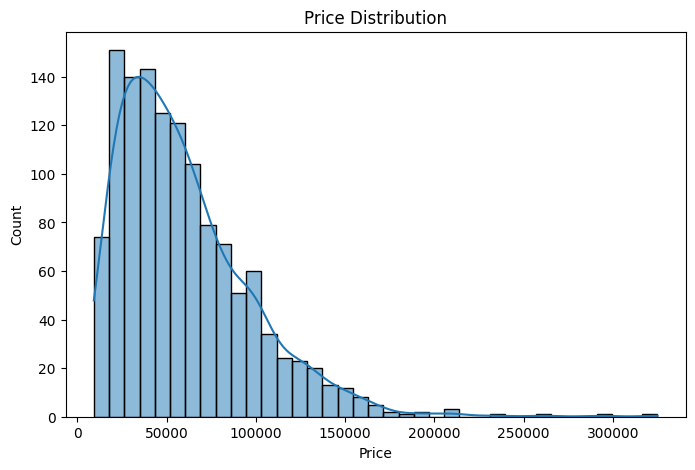

In [25]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title('Price Distribution')
plt.show()

In [26]:
df[df['Price']>200000]

,Company,TypeName,Inches,Ram,OpSys,Weight,Price,Cpu_Brand,Cpu_Model,Cpu_Speed,...,Resolution_Height,Total_Pixels,Resolution_Quality,IPS,Retina,Touchscreen,Gpu_Brand,Gpu_Type,Gpu_Model,Gpu_Number
196,Razer,Gaming,17.3,32,Windows 10,3.49,324954.720,Intel,Core i7,2.9,...,2160.0,8294400.0,High Resolution,0,0,1,Nvidia,Dedicated_or_High_Performance,GeForce GTX 1080,1080.0
238,Asus,Gaming,17.3,32,Windows 10,4.70,207259.200,Intel,Core i7,2.9,...,1080.0,2073600.0,Full HD,0,0,0,Nvidia,Dedicated_or_High_Performance,GeForce GTX 1080,1080.0
610,Lenovo,Notebook,15.6,32,Windows 10,2.50,261018.720,Intel,Xeon,3.1,...,2160.0,8294400.0,High Resolution,1,0,0,Nvidia,Dedicated_or_High_Performance,Quadro M2200M,2200.0
749,HP,Workstation,17.3,16,Windows 7,3.00,233845.920,Intel,Xeon,2.9,...,1080.0,2073600.0,Full HD,1,0,0,Nvidia,Dedicated_or_High_Performance,Quadro M2000M,2000.0
830,Razer,Gaming,17.3,32,Windows 10,3.49,292986.720,Intel,Core i7,2.9,...,2160.0,8294400.0,High Resolution,0,0,1,Nvidia,Dedicated_or_High_Performance,GeForce GTX 1080,1080.0
1066,Asus,Gaming,17.3,64,Windows 10,3.58,211788.000,Intel,Core i7,2.7,...,1080.0,2073600.0,Full HD,1,0,0,Nvidia,Dedicated_or_High_Performance,GeForce GTX 980,980.0
1136,HP,Workstation,17.3,8,Windows 7,3.00,210424.032,Intel,Core i7,2.6,...,1080.0,2073600.0,Full HD,1,0,0,Nvidia,Dedicated_or_High_Performance,Quadro M3000M,3000.0


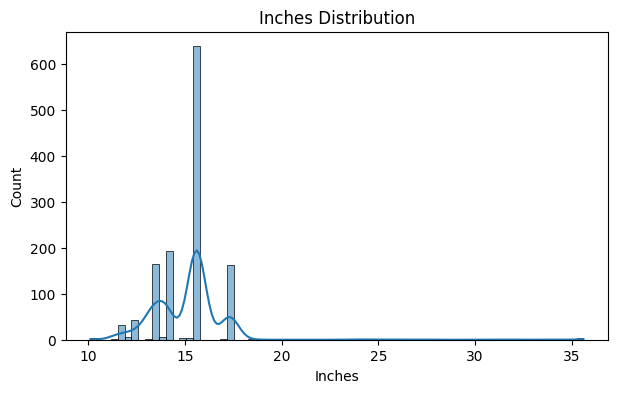

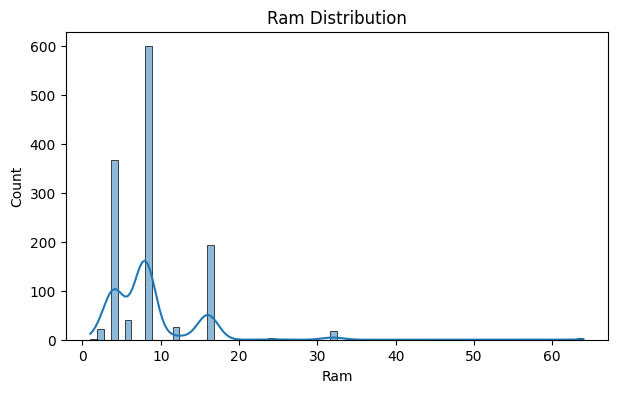

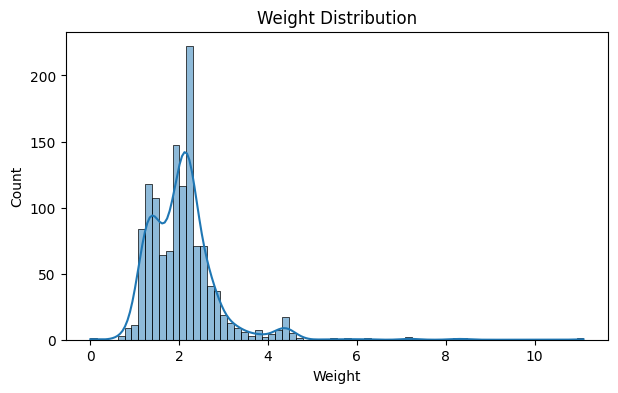

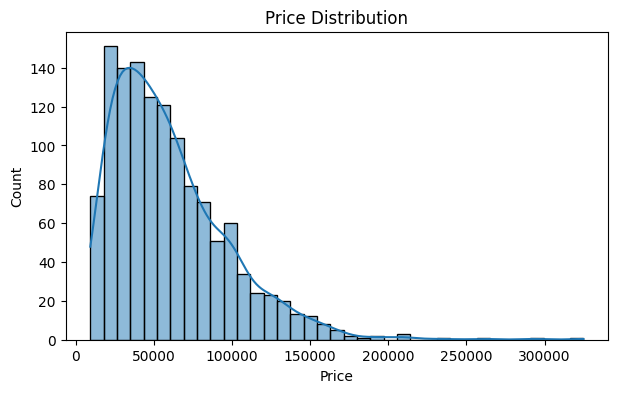

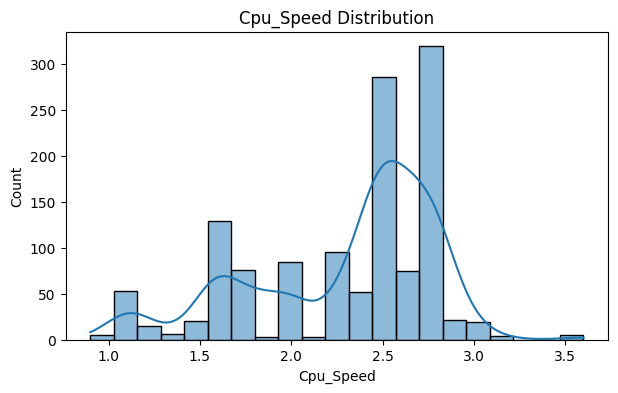

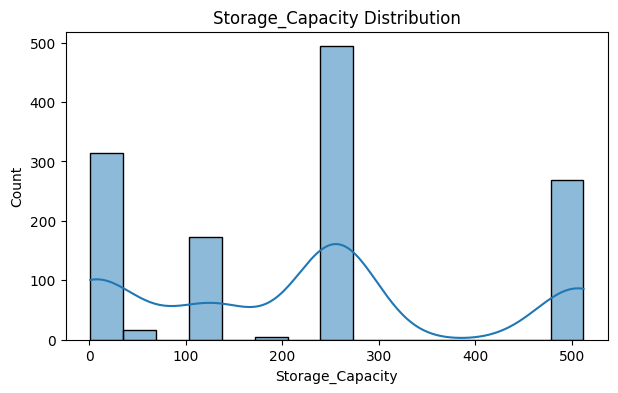

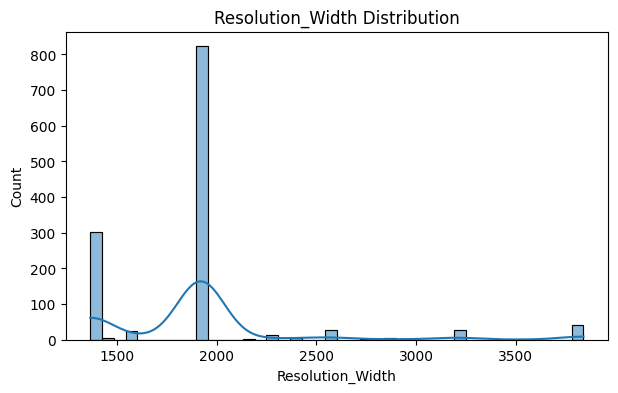

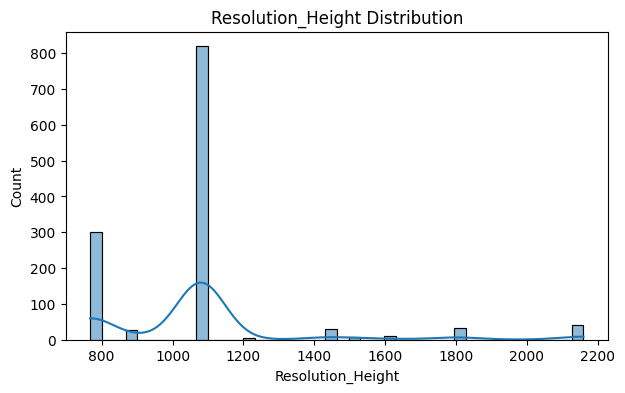

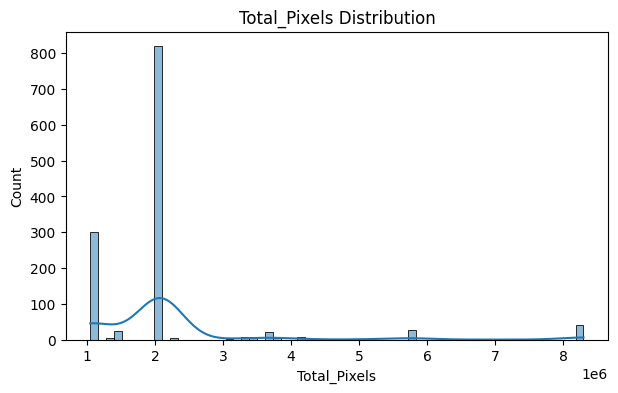

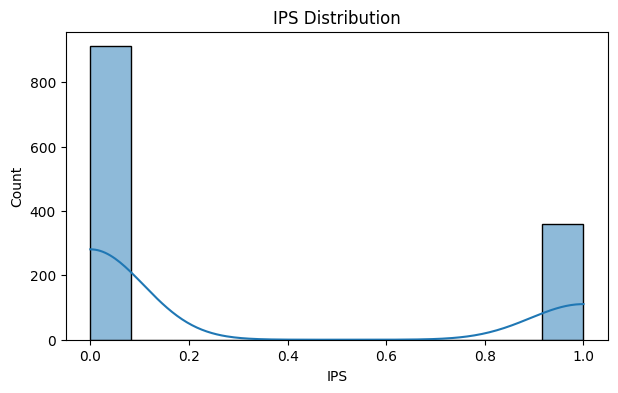

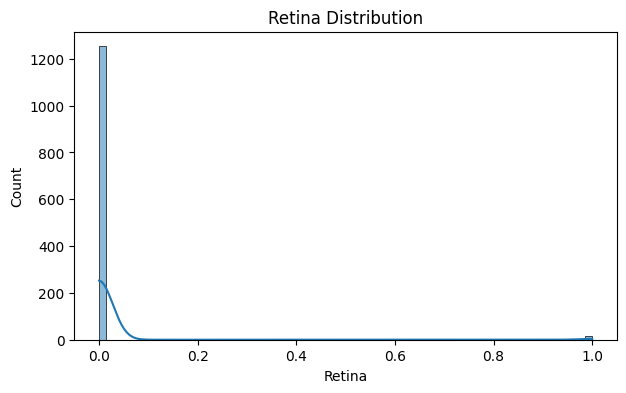

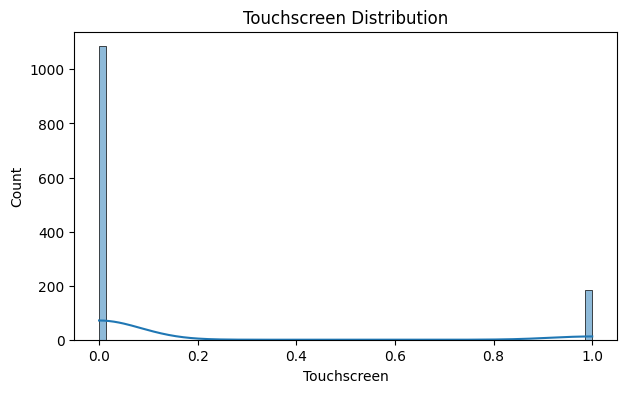

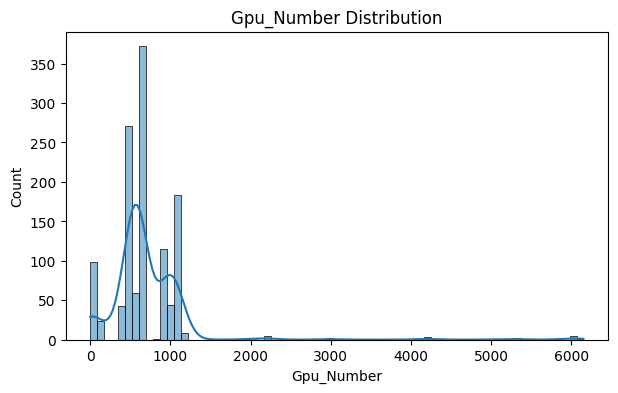

In [27]:
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'{col} Distribution')
    plt.show()

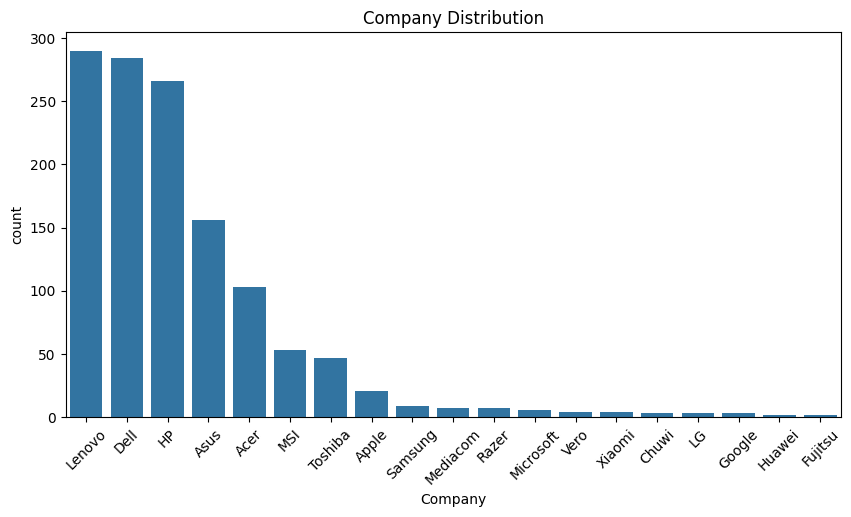

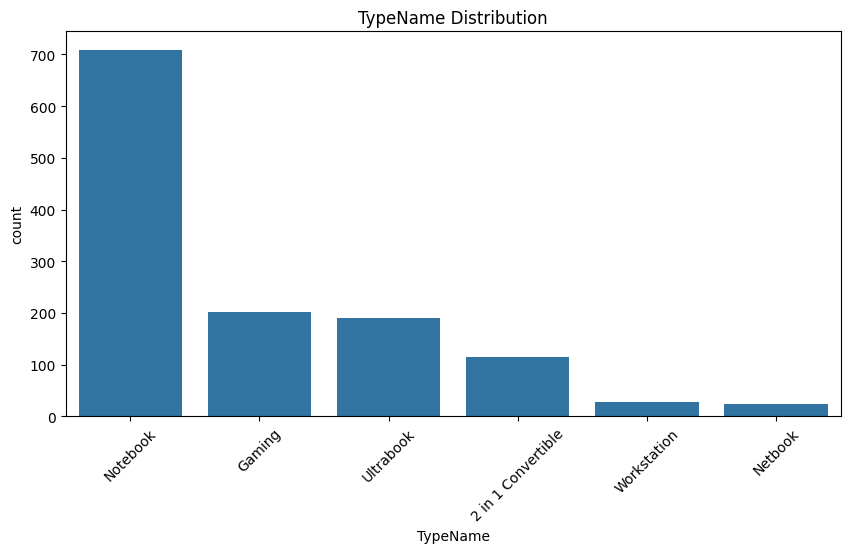

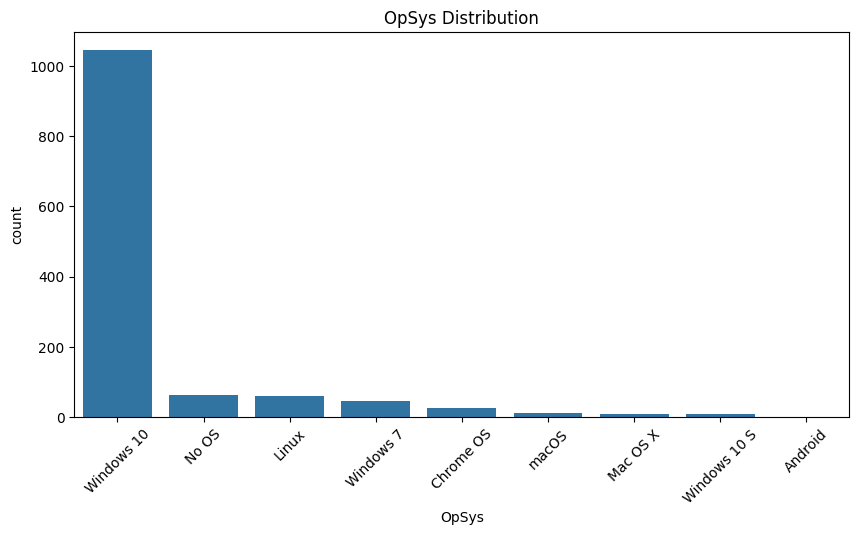

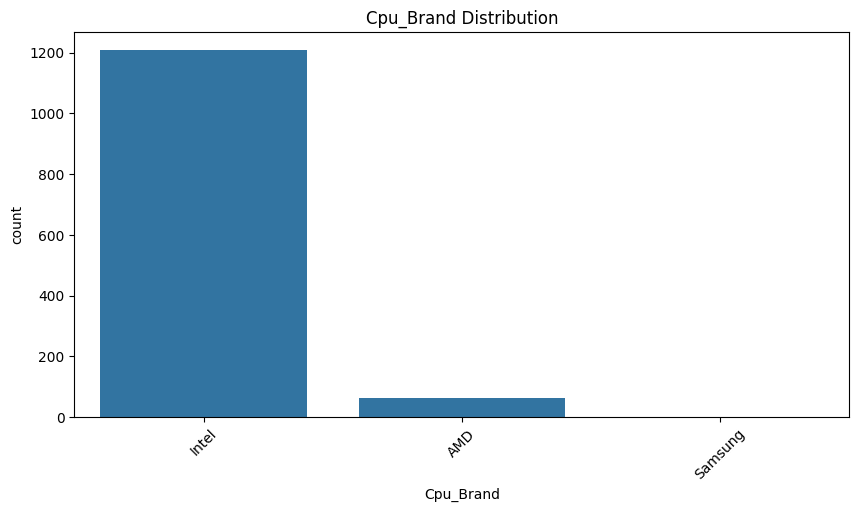

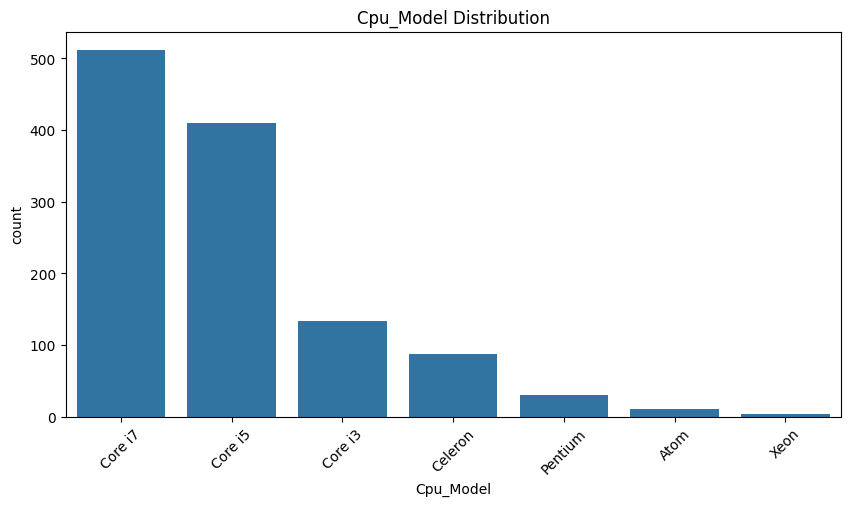

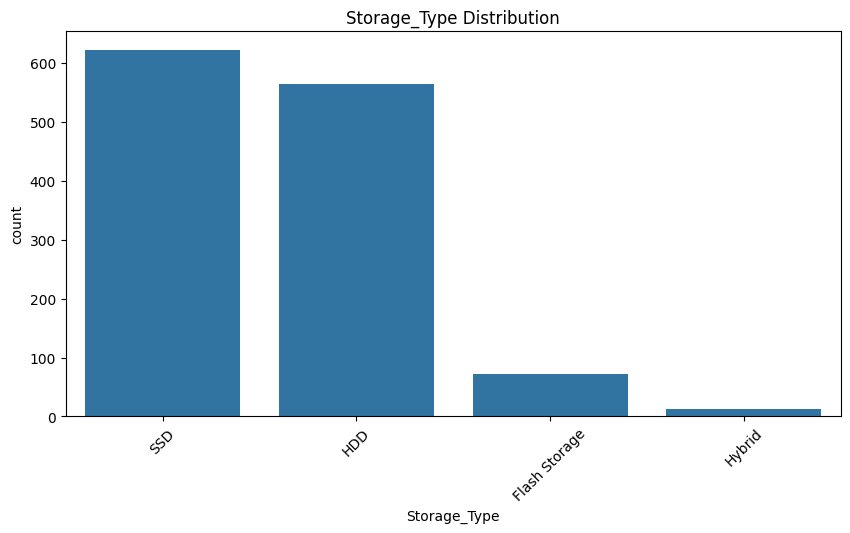

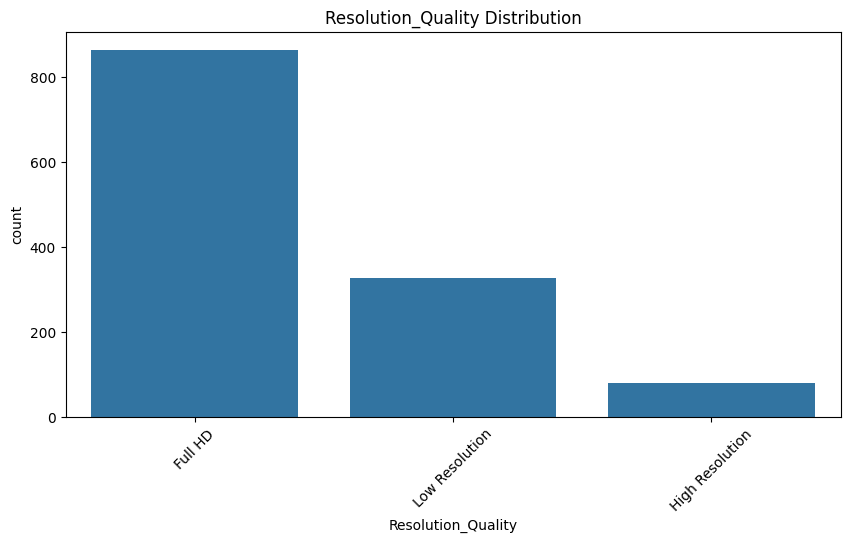

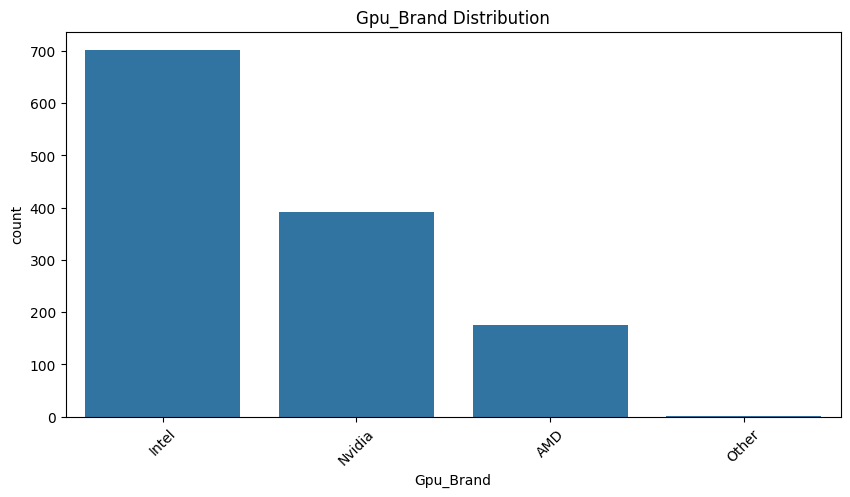

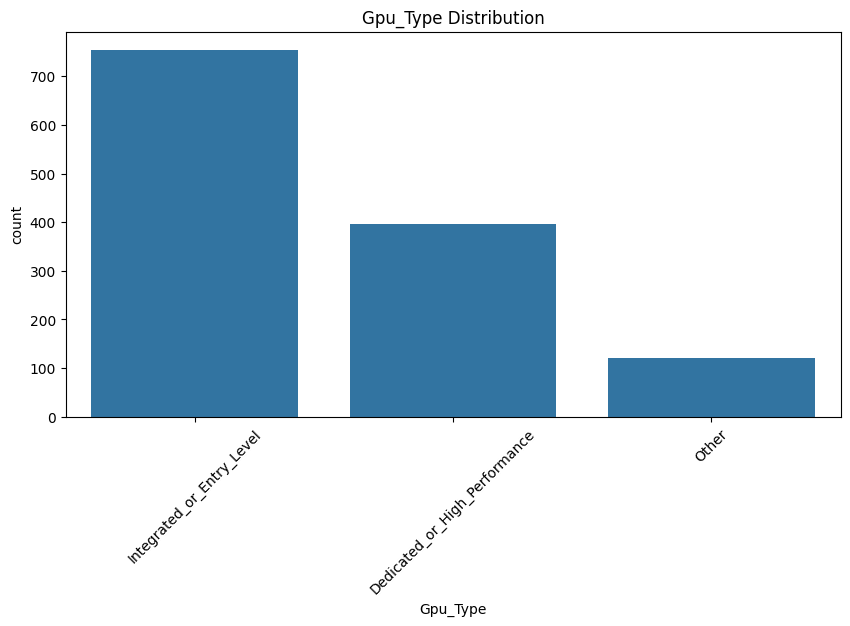

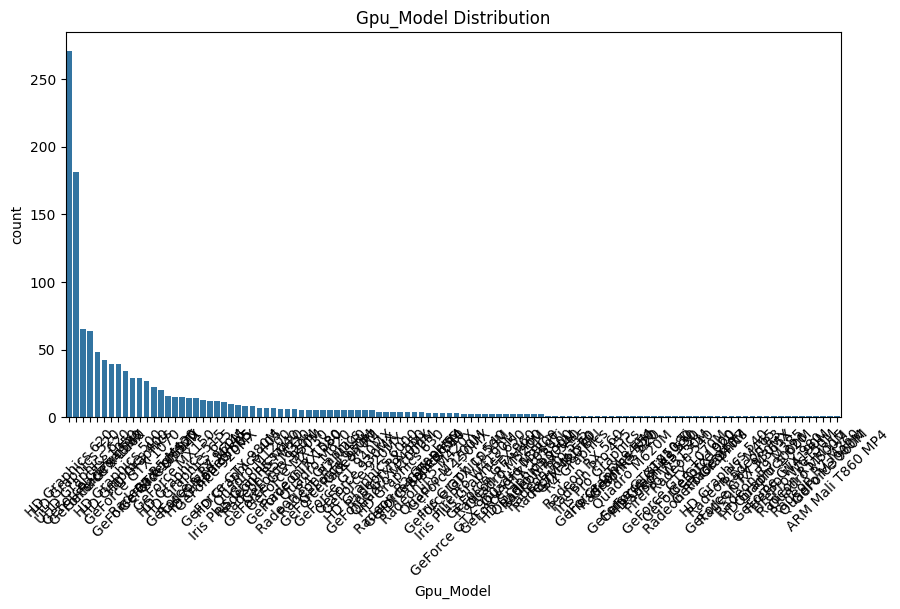

In [28]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    plt.figure(figsize=(10,5))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'{col} Distribution')
    plt.xticks(rotation=45)
    plt.show()

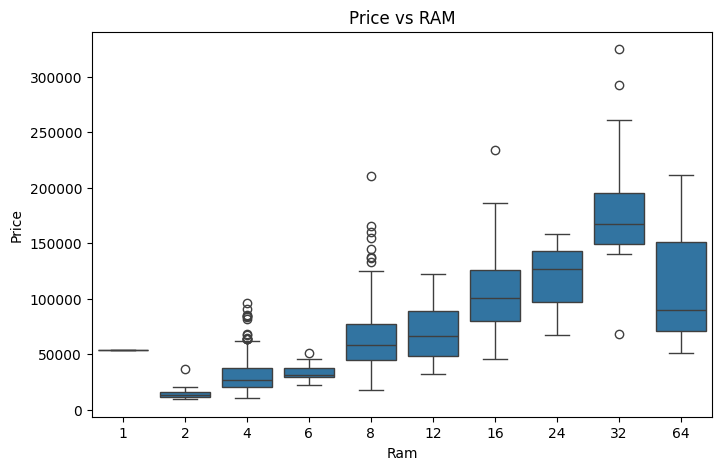

In [29]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Ram', y='Price')
plt.title('Price vs RAM')
plt.show()

In [30]:
df = df[~(
    (df['Ram'] == 32) &
    ((df['Price'] < 100000) | (df['Price'] > 200000))
)].copy()

In [31]:
df[(df['Ram']==32)&(df['Price']<100000)]


,Company,TypeName,Inches,Ram,OpSys,Weight,Price,Cpu_Brand,Cpu_Model,Cpu_Speed,...,Resolution_Height,Total_Pixels,Resolution_Quality,IPS,Retina,Touchscreen,Gpu_Brand,Gpu_Type,Gpu_Model,Gpu_Number


In [32]:
df[(df['Ram']==32)&(df['Price']>250000)]


,Company,TypeName,Inches,Ram,OpSys,Weight,Price,Cpu_Brand,Cpu_Model,Cpu_Speed,...,Resolution_Height,Total_Pixels,Resolution_Quality,IPS,Retina,Touchscreen,Gpu_Brand,Gpu_Type,Gpu_Model,Gpu_Number


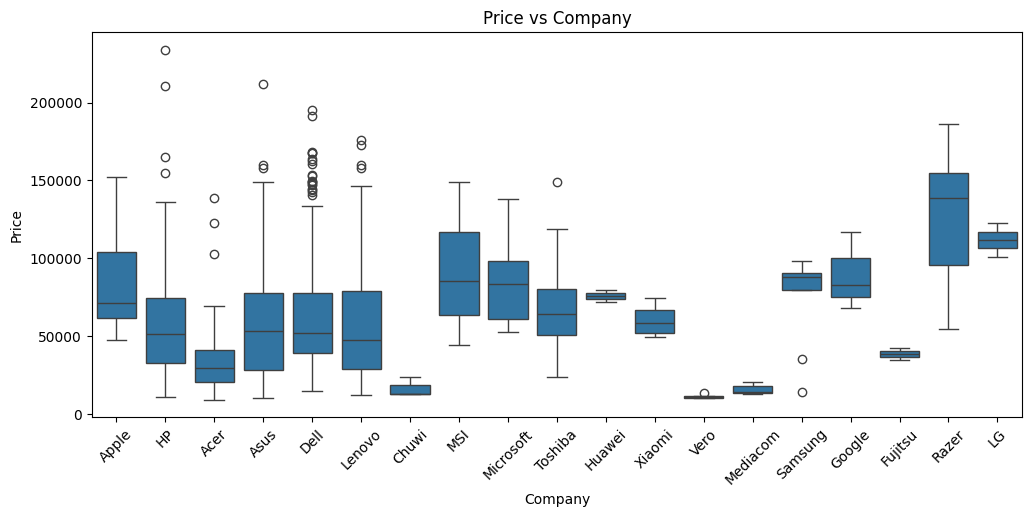

In [33]:
plt.figure(figsize=(12,5))

sns.boxplot(data=df, x='Company', y='Price')

plt.title('Price vs Company')
plt.xticks(rotation=45)
plt.show()

In [34]:
conditions = (
    ((df['Company'] == 'Samsung') & (df['Price'] < 50000)) |
    ((df['Company'] == 'Toshiba') & (df['Price'] > 140000)) |
    ((df['Company'] == 'HP') & (df['Price'] > 145000)) |
    ((df['Company'] == 'Lenovo') & (df['Price'] > 147000)) |
    ((df['Company'] == 'Acer') & (df['Price'] > 90000)) |
    ((df['Company'] == 'Asus') & (df['Price'] > 147000))
)

df = df[~conditions].copy()



In [35]:
cat_cols = [
    'Company',
    'TypeName',
    'OpSys',
    'Cpu_Brand',
    'Cpu_Model',
    'Storage_Type',
    'Resolution_Quality',
    'Gpu_Brand',
    'Gpu_Type',
    'Gpu_Model'
]
df = pd.get_dummies(
    df,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

In [45]:
X.isnull().sum().sort_values(ascending=False)

,0
Gpu_Number,30
Inches,0
Ram,0
Cpu_Speed,0
Weight,0
...,...
Gpu_Model_Radeon RX 540,0
Gpu_Model_Radeon RX 550,0
Gpu_Model_Radeon RX 560,0
Gpu_Model_Radeon RX 580,0


In [46]:
X = df.drop(columns=['Price', 'Unnamed: 0','Gpu_Number'], errors='ignore')
y = df['Price']

In [37]:
X.columns

Index(['Inches', 'Ram', 'Weight', 'Cpu_Speed', 'Storage_Capacity',
       'Resolution_Width', 'Resolution_Height', 'Total_Pixels', 'IPS',
       'Retina',
       ...
       'Gpu_Model_Radeon R7 M440', 'Gpu_Model_Radeon R7 M445',
       'Gpu_Model_Radeon R7 M460', 'Gpu_Model_Radeon R7 M465',
       'Gpu_Model_Radeon R9 M385', 'Gpu_Model_Radeon RX 540',
       'Gpu_Model_Radeon RX 550', 'Gpu_Model_Radeon RX 560',
       'Gpu_Model_Radeon RX 580', 'Gpu_Model_UHD Graphics 620'],
      dtype='object', length=161)

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=100)

In [49]:
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

In [50]:
X.head()

,Inches,Ram,Weight,Cpu_Speed,Storage_Capacity,Resolution_Width,Resolution_Height,Total_Pixels,IPS,Retina,...,Gpu_Model_Radeon R7 M440,Gpu_Model_Radeon R7 M445,Gpu_Model_Radeon R7 M460,Gpu_Model_Radeon R7 M465,Gpu_Model_Radeon R9 M385,Gpu_Model_Radeon RX 540,Gpu_Model_Radeon RX 550,Gpu_Model_Radeon RX 560,Gpu_Model_Radeon RX 580,Gpu_Model_UHD Graphics 620
0,13.3,8,1.37,2.3,128.0,2560.0,1600.0,4096000.0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,13.3,8,1.34,1.8,128.0,1440.0,900.0,1296000.0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,15.6,8,1.86,2.5,256.0,1920.0,1080.0,2073600.0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,15.4,16,1.83,2.7,512.0,2880.0,1800.0,5184000.0,1,1,...,0,0,0,0,0,0,0,0,0,0
4,13.3,8,1.37,3.1,256.0,2560.0,1600.0,4096000.0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [51]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [52]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

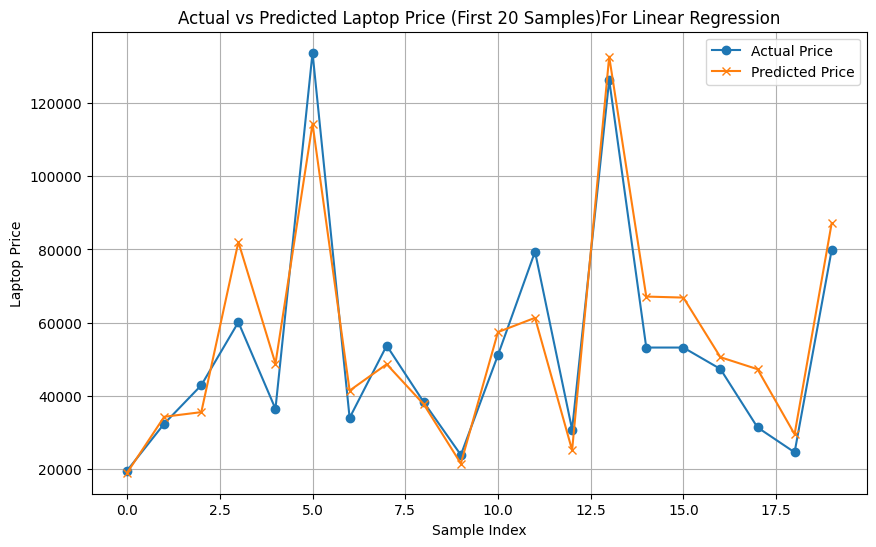

  7%|▋         | 1/15 [00:00<00:05,  2.55it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.107e+09, tolerance: 1.133e+08
  model = cd_fast.enet_coordinate_descent(


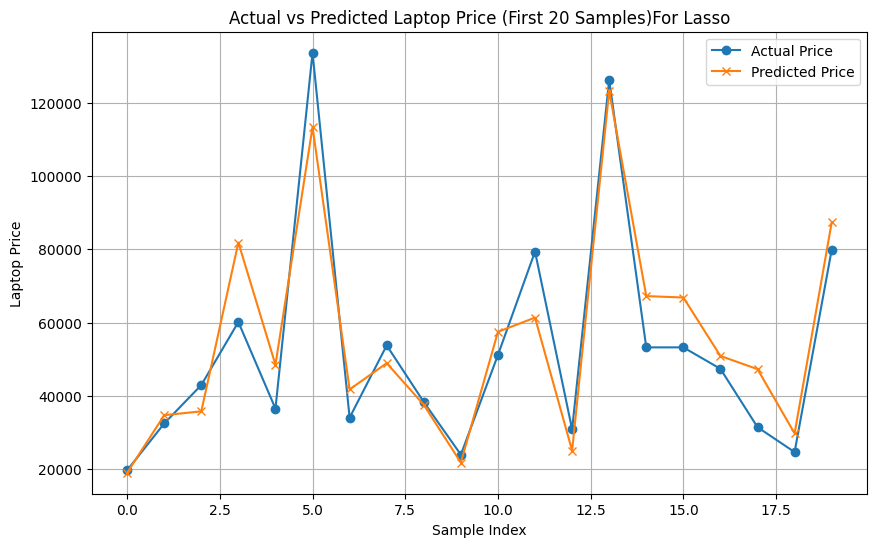

 13%|█▎        | 2/15 [00:01<00:11,  1.08it/s]

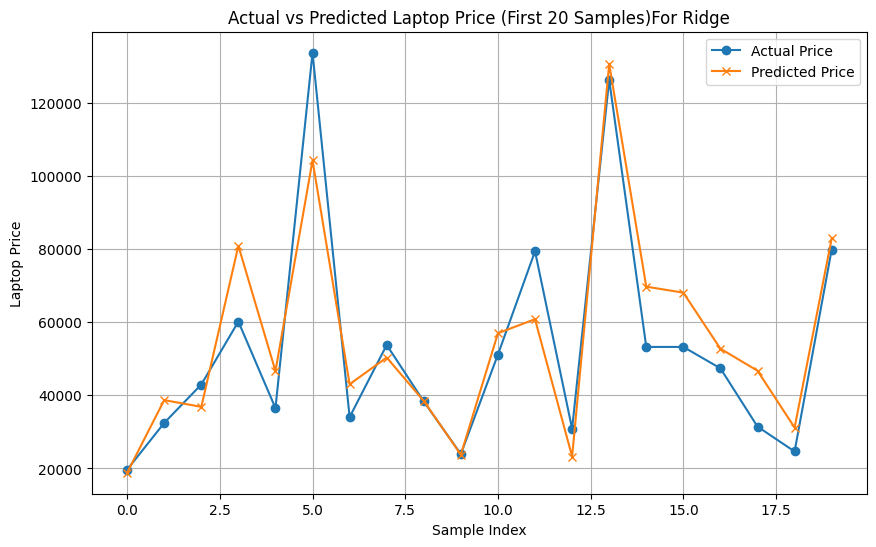

 20%|██        | 3/15 [00:02<00:10,  1.13it/s]

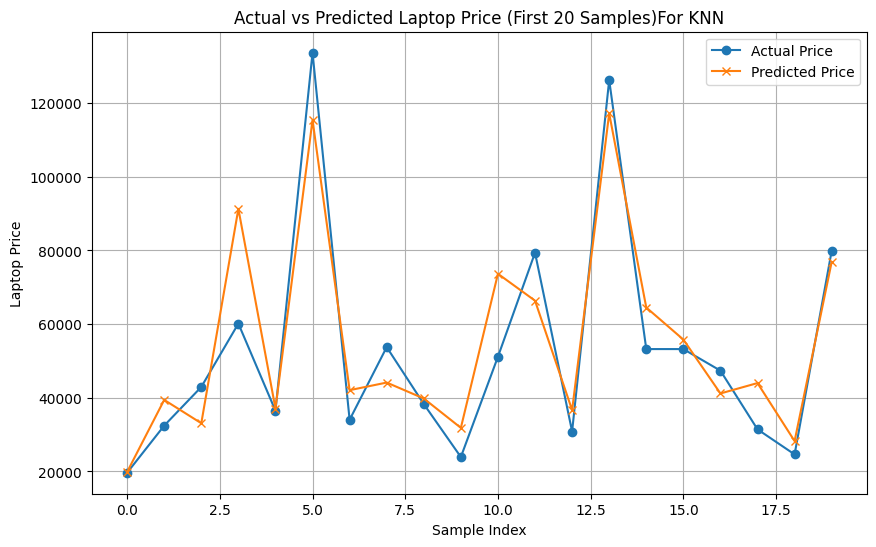

 27%|██▋       | 4/15 [00:03<00:10,  1.06it/s]

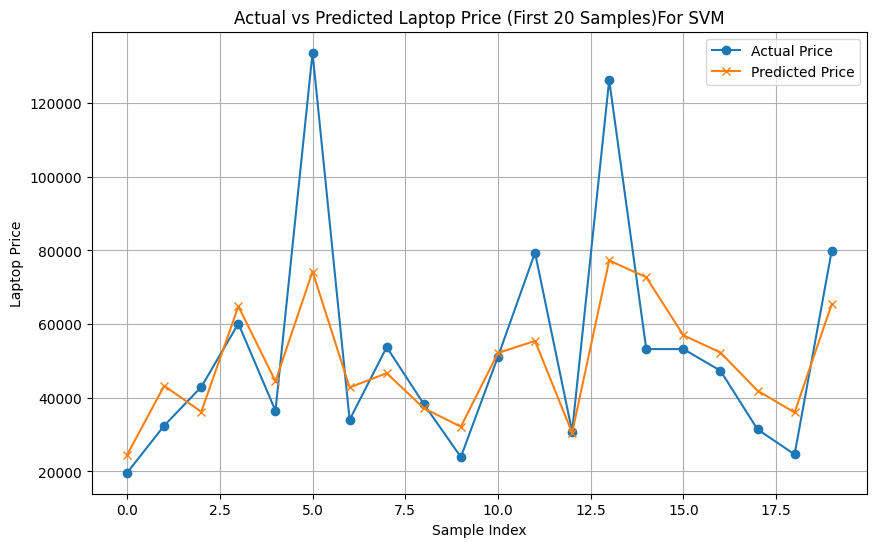

 33%|███▎      | 5/15 [00:03<00:07,  1.34it/s]

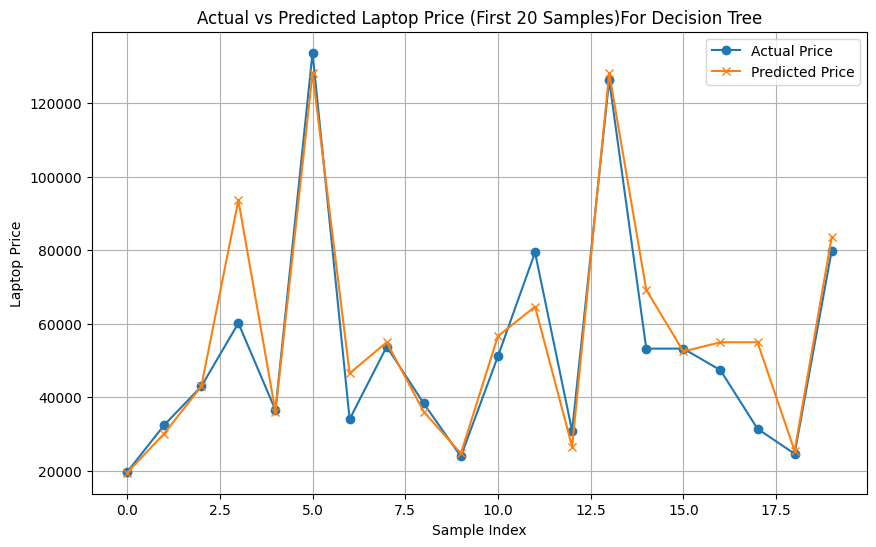

 40%|████      | 6/15 [00:04<00:05,  1.79it/s]

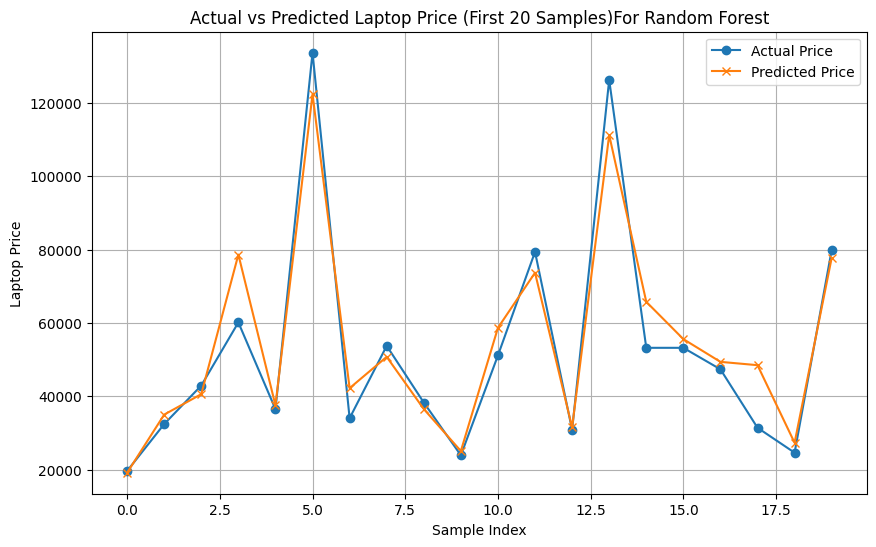

 47%|████▋     | 7/15 [00:04<00:04,  1.77it/s]

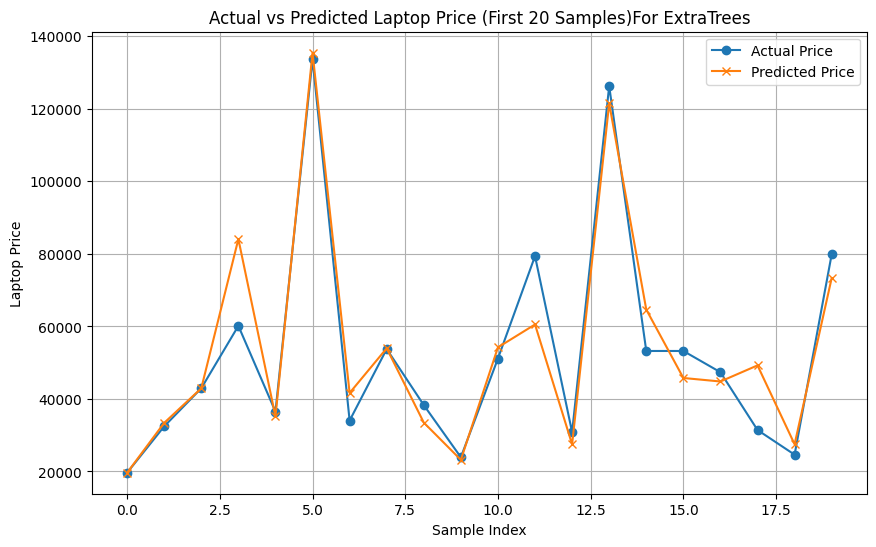

 53%|█████▎    | 8/15 [00:06<00:05,  1.22it/s]

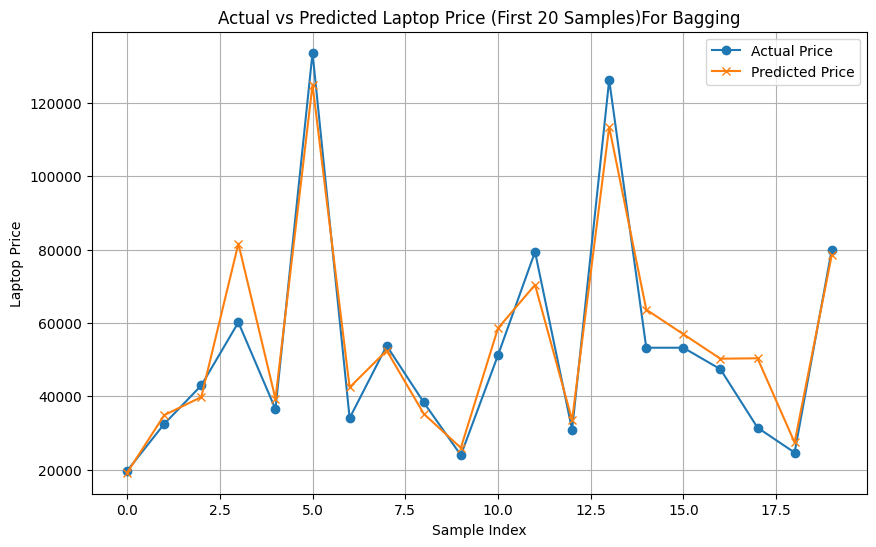

 60%|██████    | 9/15 [00:06<00:04,  1.31it/s]

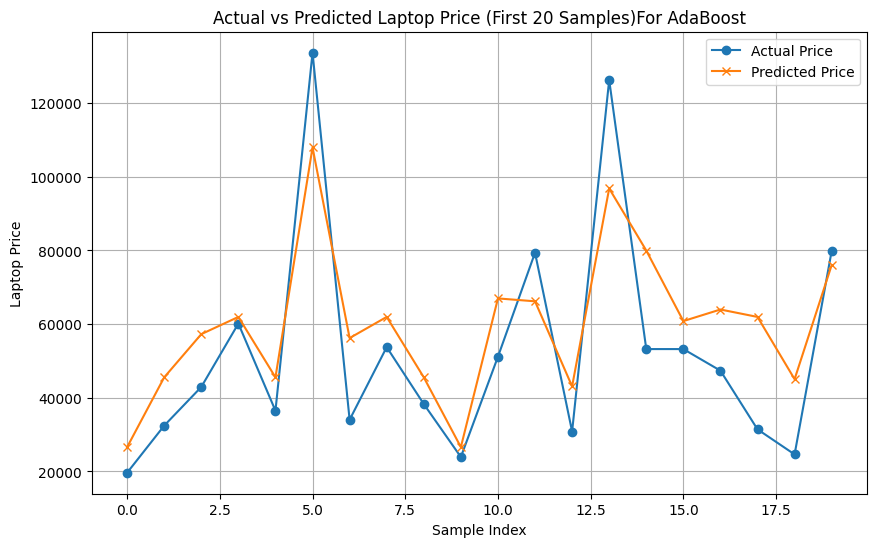

 67%|██████▋   | 10/15 [00:07<00:03,  1.61it/s]

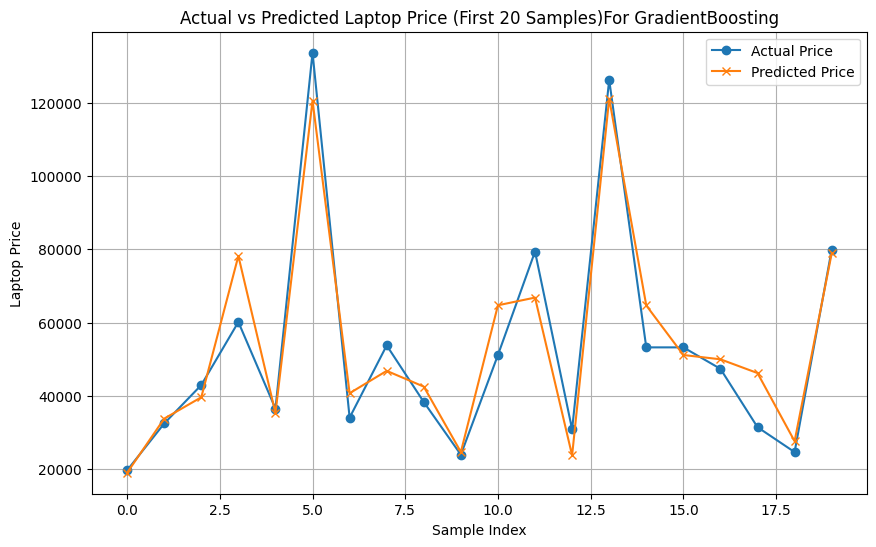

 73%|███████▎  | 11/15 [00:07<00:02,  1.71it/s]

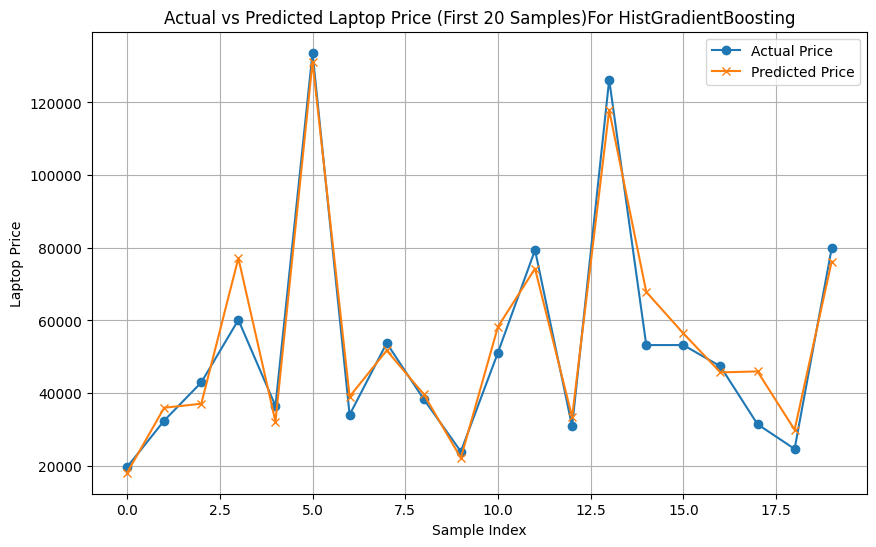

 80%|████████  | 12/15 [00:08<00:02,  1.38it/s]

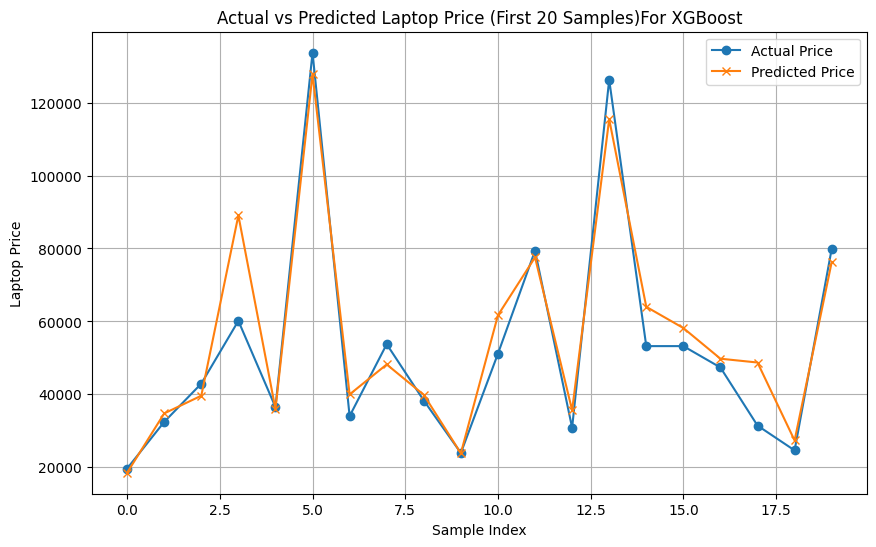

 87%|████████▋ | 13/15 [00:09<00:01,  1.55it/s]

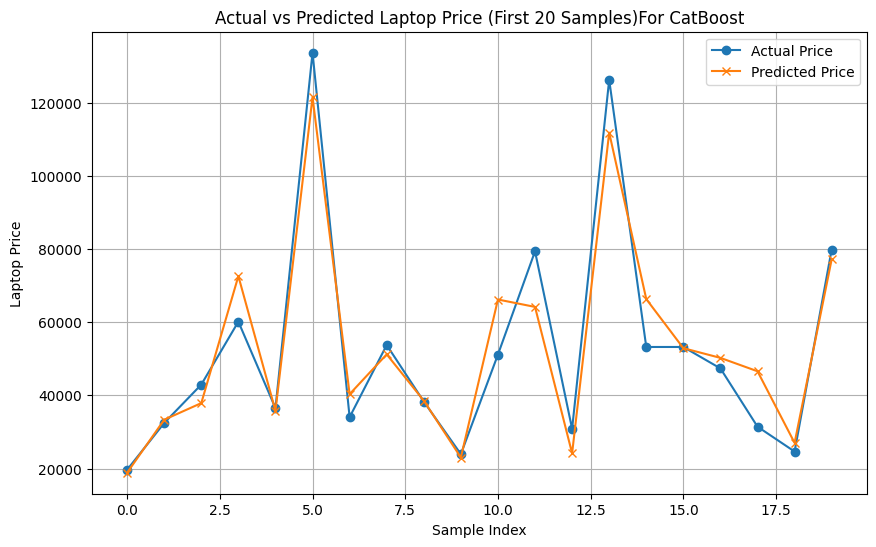

 93%|█████████▎| 14/15 [00:09<00:00,  1.71it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002481 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 289
[LightGBM] [Info] Number of data points in the train set: 997, number of used features: 52
[LightGBM] [Info] Start training from score 59104.728744


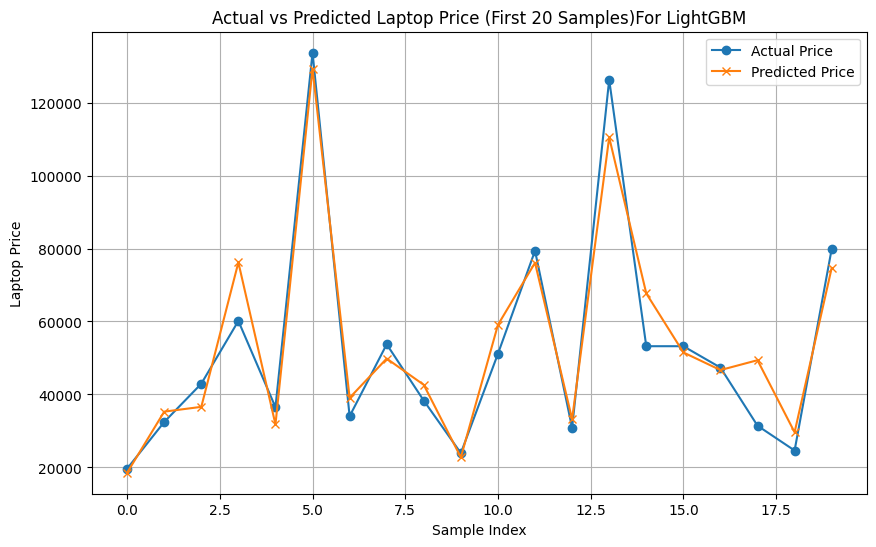

100%|██████████| 15/15 [00:09<00:00,  1.53it/s]


In [53]:

errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Laptop Price')
    plt.title('Actual vs Predicted Laptop Price (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()


In [54]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [55]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [56]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
HistGradientBoosting,4937.836639,7163.355367,5.095282e+07,1.047551e+08,7138.124126,10234.994260,0.955166,0.892717
LightGBM,4951.647496,7216.119355,5.038377e+07,1.054422e+08,7098.152751,10268.505842,0.955667,0.892013
XGBoost,4747.713521,7557.023303,4.560772e+07,1.113913e+08,6753.348742,10554.205972,0.959870,0.885921
Bagging,5580.281545,7910.925526,6.035981e+07,1.241769e+08,7769.157714,11143.470534,0.946889,0.872827
Random Forest,5504.267902,7829.031362,5.910496e+07,1.244523e+08,7687.975336,11155.819883,0.947993,0.872544
Simple Voting,4032.833815,7216.119355,3.198601e+07,1.054422e+08,5655.617630,10268.505842,0.971855,0.870599
Voting,4032.833815,7216.119355,3.198601e+07,1.054422e+08,5655.617630,10268.505842,0.971855,0.870599
CatBoost,8130.827713,8441.055074,1.214900e+08,1.279096e+08,11022.249165,11309.710492,0.893101,0.869004
GradientBoosting,7860.377056,8576.110726,1.116303e+08,1.333801e+08,10565.526416,11549.029834,0.901776,0.863401
Weighted Voting,4307.367695,7216.119355,3.655875e+07,1.054422e+08,6046.382825,10268.505842,0.967832,0.862735


<Axes: >

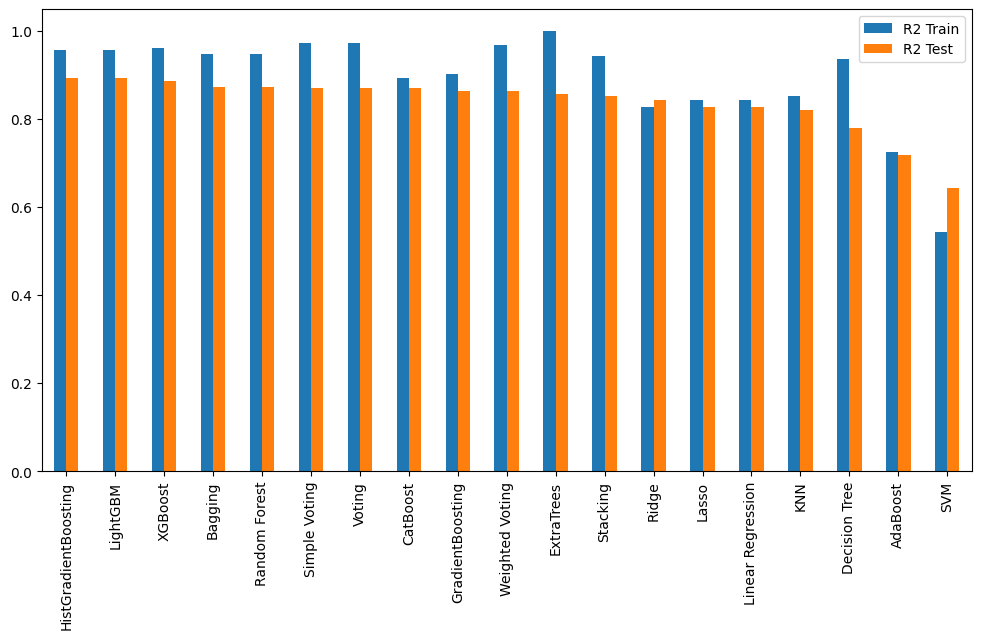

In [57]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

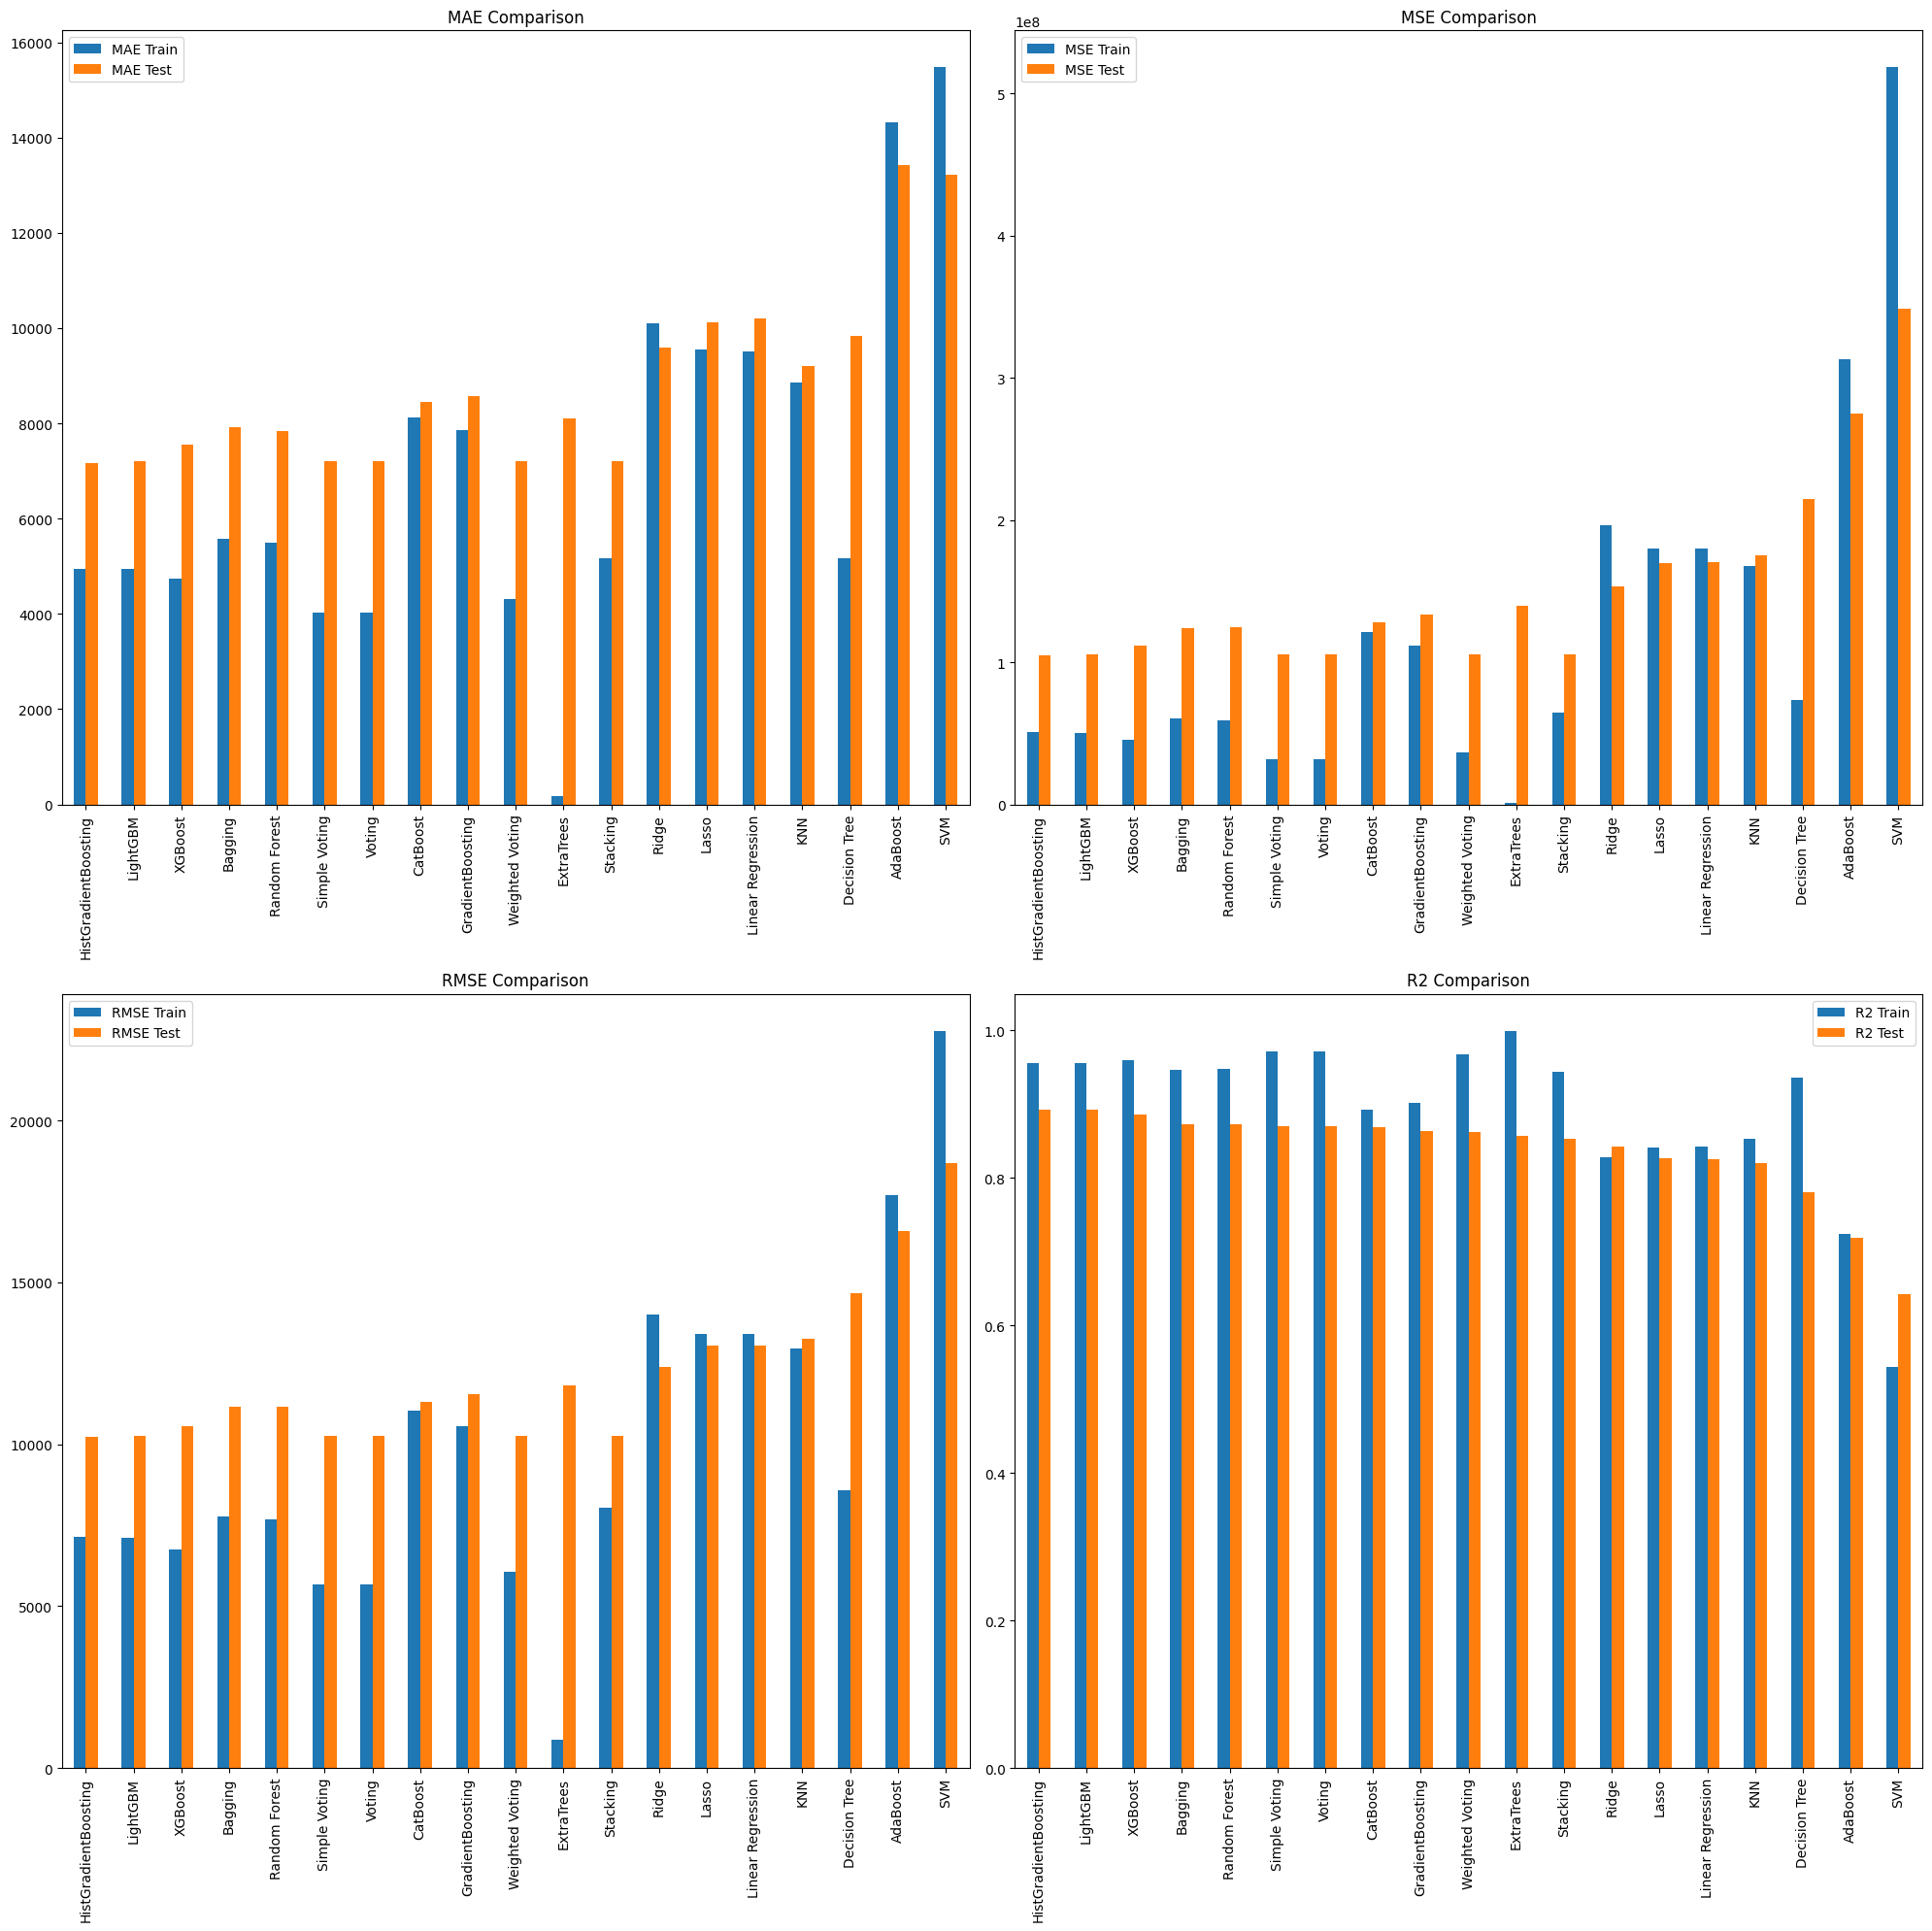

In [58]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()